   StudyHours  Attendance  ExamScore  FinalGrade
0          19          64         40           3
1          19          64         66           2
2          19          64         99           0
3          19          64         40           3
4          19          64         66           2
(14003, 4)


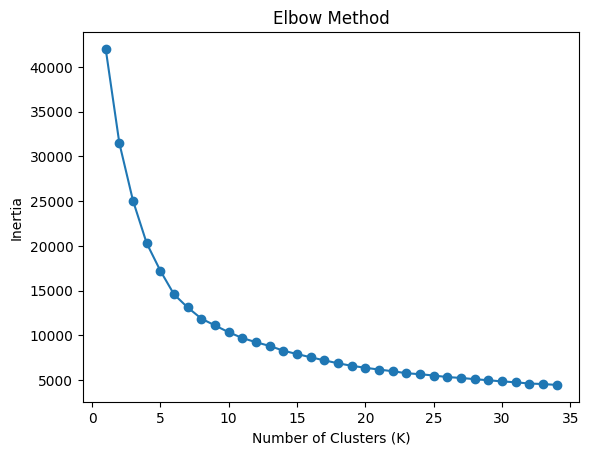

   StudyHours  Attendance  ExamScore  FinalGrade  Cluster
0          19          64         40           3        3
1          19          64         66           2        1
2          19          64         99           0        1
3          19          64         40           3        3
4          19          64         66           2        1
Cluster
0    3675
1    3604
2    3389
3    3335
Name: count, dtype: int64


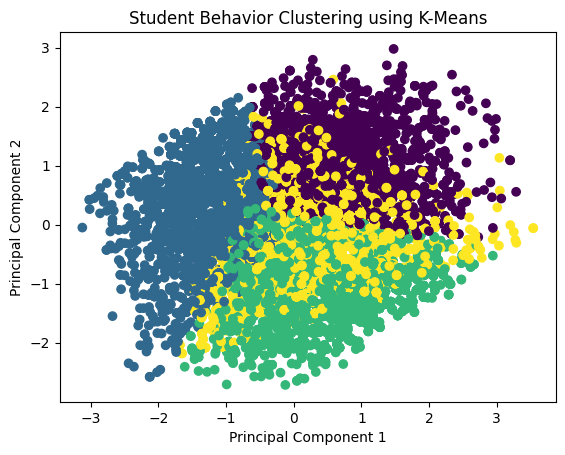

In [25]:
# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


# 2. Load dataset

df = pd.read_csv("student_performance_upate.csv")

print(df.head())
print(df.shape)


# 3. Select features for clustering

X = df[["StudyHours", "Attendance", "ExamScore"]]


# 4. Scale the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 5. Elbow Method to find the best number of clusters

inertia = []

for k in range(1, 35):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)


# 6. Plot Elbow Curve

plt.plot(range(1, 35), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


# 7. Apply K-Means

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)


# 8. Display students with their clusters

print(df.head())


# 9. Check number of students in each cluster

print(df["Cluster"].value_counts())


# 10. PCA for visualization

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


# 11. Plot clusters

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Behavior Clustering using K-Means")
plt.show()

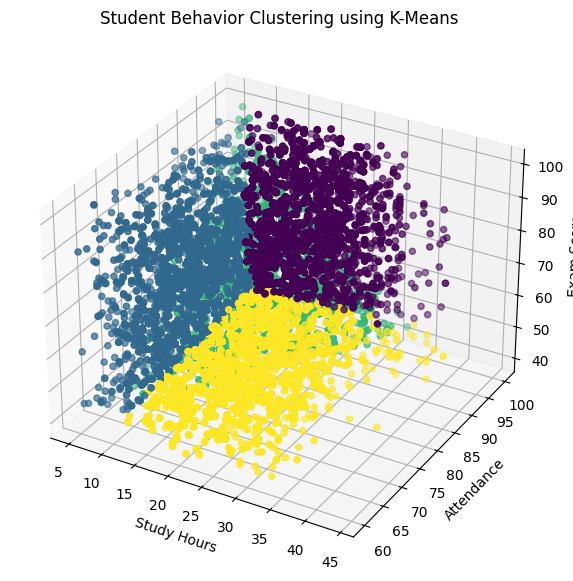

In [29]:
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X["StudyHours"],
    X["Attendance"],
    X["ExamScore"],
    c=df["Cluster"],
    s=20
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance")
ax.set_zlabel("Exam Score")

ax.set_title("Student Behavior Clustering using K-Means")

plt.show()